In [28]:
import sys
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [5]:
model_simulations_path = os.path.abspath("../model_simulations")

# Add to sys.path if not already present
if model_simulations_path not in sys.path:
    sys.path.append(model_simulations_path)

print("Added to path:", model_simulations_path)
from saving_loading import find_scenarios, load_all_scenarios

scenarios_directory = os.path.join('..', 'model_simulations', 'scenarios')
fish_data, clone_data = load_all_scenarios('real', directory = scenarios_directory)

Added to path: /Users/connor/Documents/github/sperm-data-analysis/model_simulations


In [11]:
all_data = pd.read_csv('../experiments/11.24.2025_07.32_AM/final_data.csv')

In [43]:
sample1 = all_data[all_data['sample'] == 1]
barcodes_per_fish = sample1.groupby(['fish'], as_index = False).agg({'barcode': 'nunique'})
barcodes_per_fish.head()

,fish,barcode
0,fish1,8
1,fish10,2
2,fish13,14
3,fish14,12
4,fish15,9


Mean: 8.29, std: 3.98.


(array([2., 1., 1., 1., 2., 1., 4., 0., 2., 3.]),
 array([ 1. ,  2.3,  3.6,  4.9,  6.2,  7.5,  8.8, 10.1, 11.4, 12.7, 14. ]),
 <BarContainer object of 10 artists>)

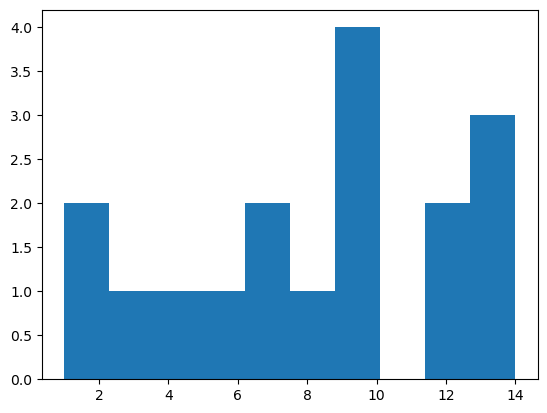

In [39]:
n_bc = barcodes_per_fish['barcode']

mean = np.mean(n_bc)
std = np.std(n_bc)

print(f'Mean: {mean:.2f}, std: {std:.2f}.')

plt.hist(barcodes_per_fish['barcode'])

In [45]:
samples_per_fish = all_data.groupby(['fish'], as_index = False).agg({'sample': 'nunique'})
samples_per_fish.head()

,fish,sample
0,fish1,11
1,fish10,14
2,fish12,12
3,fish13,4
4,fish14,14


In [49]:
samples_per_fish['sample'].max()

16

(array([4., 3., 1., 4., 3., 1., 3., 0., 2., 6.]),
 array([ 3. ,  4.3,  5.6,  6.9,  8.2,  9.5, 10.8, 12.1, 13.4, 14.7, 16. ]),
 <BarContainer object of 10 artists>)

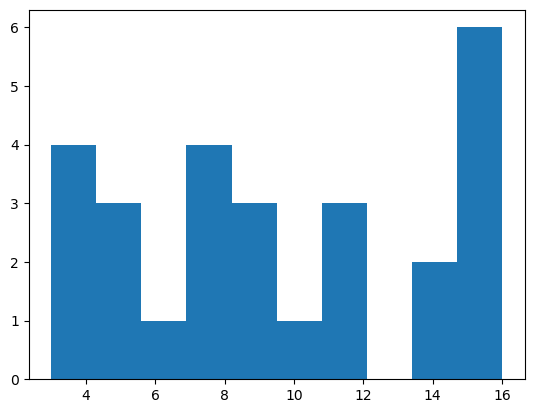

In [47]:
plt.hist(samples_per_fish['sample'])